# Tokyo Airbnb Investment Analysis /  東京のAirbnb投資分析
### Data-driven insights for Airbnb investment in Tokyo / データに基づく東京でのAirbnb投資のためのインサイト



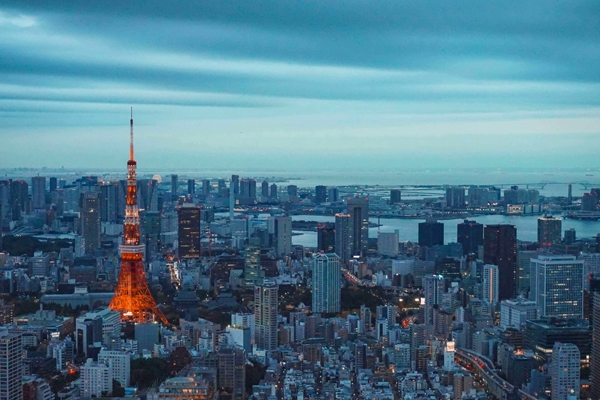


## Introduction

Short-term rentals on platforms such as Airbnb are one option for property investors in Tokyo, but revenue potential differs by area. This analysis compares areas using Inside Airbnb data for Tokyo (December 2024, over 20,000 listings).
**Question: Which Tokyo areas (wards and cities) have the highest estimated revenue potential for short-term rentals?**

**Approach:** Annual revenue per listing is estimated in two ways, from calendar availability and from review counts, and compared across areas. Purchase prices and operating costs are outside the scope of this stage.

東京の観光業が活況を呈する中、Airbnbなどのプラットフォームを通じた短期賃貸は、収益性の高い投資先として注目されています。しかし、すべてのエリアが同じように高いリターンを期待できるわけではありません。
本分析では、以下の問いに答えることを目的としています：
**「東京のどのエリア（区・市）が、短期賃貸で最も高い推定売上の可能性を持っているか。」**
**手法：** 物件ごとの年間売上を、カレンダー上の空き状況とレビュー件数の2通りで推定し、エリア間で比較します。物件の購入価格や運営コストは、この段階では対象外としています。

**Goal:** To give potential investors a data-based first screening of Tokyo areas by estimated revenue potential. The result is a ranking of areas that can be combined with property prices and operating costs in a later stage.

**目的：** 投資を検討する人が、推定売上の観点から東京のエリアを絞り込むための、データに基づく最初の判断材料を提供すること。結果として得られるエリアのランキングは、物件価格や運営コストと組み合わせることで、次の段階の分析に活用できます。

## Data and sample

**Data:** Inside Airbnb's Tokyo listings, scraped in December 2024 (over 20,000 listings). The data has no booking records, so demand is estimated from reviews and availability. Source: https://insideairbnb.com/get-the-data/

**Sample:** short-stay listings (minimum stay under 10 nights) with at least one review in the last 12 months, in areas with more than 20 such listings ([N] listings).

**Main cleaning decisions:**
- Missing prices (about 11%) were filled with the median for the same area, property type and number of bedrooms.
- Price outliers above about ¥[upper] were removed (1.5 × IQR rule).

Full data preparation steps are in Appendix A.


## データと分析対象

**データ：** Inside Airbnbが公開している東京の物件データ（2024年12月取得、2万件以上）を使用しました。データに予約記録は含まれないため、需要はレビューと空き状況から推定しています。出典：https://insideairbnb.com/get-the-data/

**分析対象：** 最低宿泊日数が10日未満の短期滞在物件のうち、過去12か月に1件以上のレビューがあり、かつ該当物件が20件を超えるエリアにある物件（[N]件）。

**主なクリーニングの判断：**
- 価格の欠損（約11%）は、同じエリア・物件タイプ・寝室数の中央値で補完しました。
- 約[upper]円を超える価格の外れ値を除外しました（四分位範囲の1.5倍の基準）。

データ準備の詳細な手順は付録Aに記載しています。

## Exploratory Data Analysis / 探索的データ分析 

- Price Distribution: Visualized nightly rates across neighborhoods and room types.
- Listing Density: Mapped top 10 areae with the highest concentration of listings.
- Revenue Estimation: Used review frequency and availability to estimate potential revenue.

- 価格分布：エリア・部屋タイプごとの1泊料金を可視化
- 物件密度：市内におけるAirbnb物件の分布をマッピング
- 収益推定：レビュー頻度と利用可能日数から収益を推定
- 料金の傾向：価格全体の傾向を確認

### Rates Overview / 料金の概要

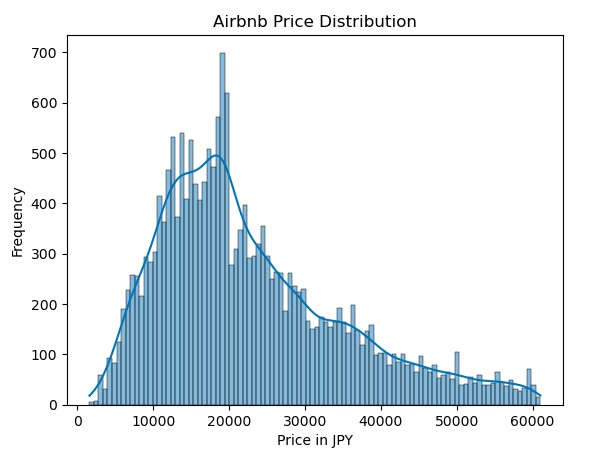

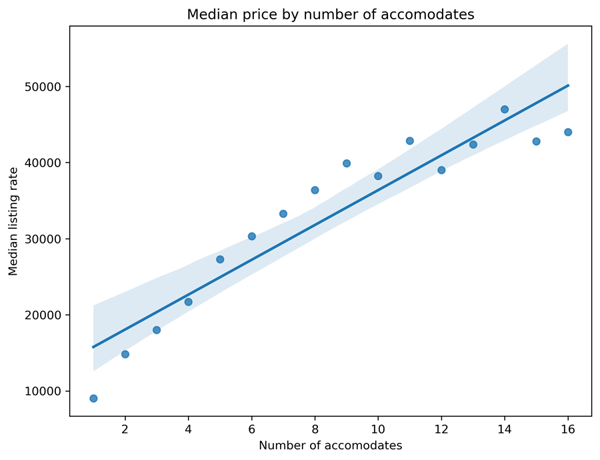

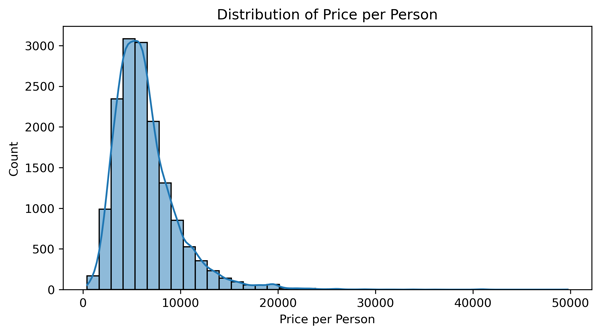

### Key Findings / 主な発見

- Average nightly price: ¥23,659 (median ¥[median])
- Most common room type: entire home/apartment
- Areas with the most listings: Shinjuku, Shibuya, Minato
- Among the ten most-listed areas, the highest median rates: Minato, Shibuya, Taito

- 1泊あたりの平均料金：23,659円（中央値[median]円）
- 最も多い部屋タイプ：まるごと貸し（Entire home/apt）
- 物件数が多いエリア：新宿区、渋谷区、港区
- 物件数上位10エリアのうち、中央値が高いエリア：港区、渋谷区、台東区

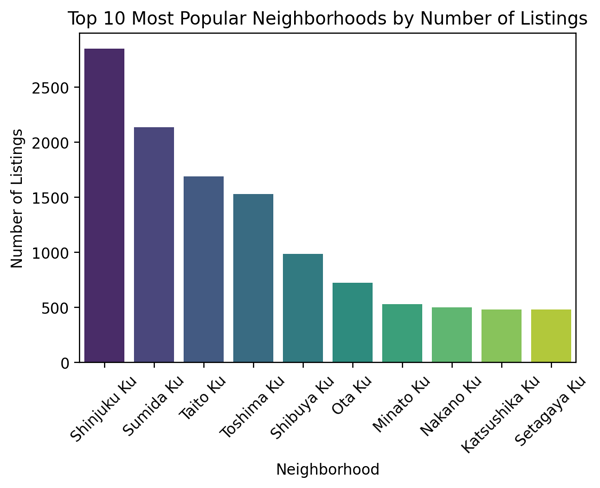

- **Top neighborhoods by median price / 中央値価格が高いエリア:** Minato, Shibuya, Taito
- **Top neighborhoods by occupancy / 稼働率が高いエリア:** Shinjuku, Sumida, Taito
- **Highest location reviews / ロケーションのレビュー評価が高いエリア:** Minato, Chiyoda, Setagaya, Shibuya

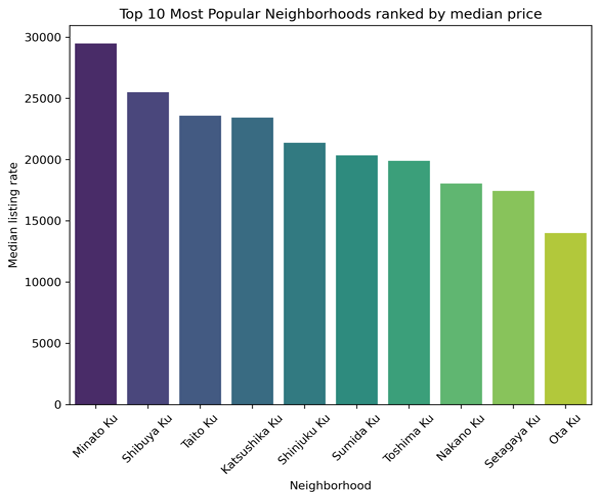

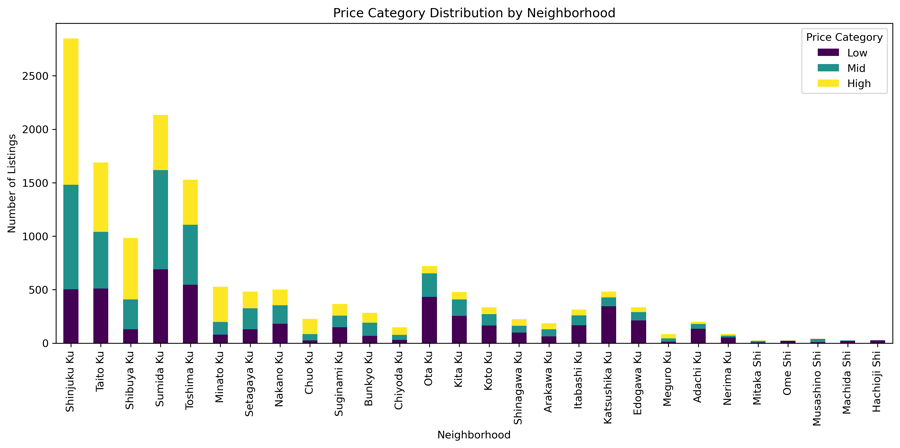

The above chart categorizes property prices by area. Centrally located neighborhoods with higher real estate prices tend to attract high-end and mid-range listings, while more affordable properties in the outskirts offer a large share of low-priced listings.<br>
上のグラフは、地域ごとの物件価格を分類したものです。中心地にある不動産価格の高いエリアには、高級または中価格帯のリスティングが多く集まり、郊外の価格が安いエリアでは、低価格のリスティングが多くなっています。

**Recommendation:** It is important to carefully consider the type of property you want to focus on. High-end listings require a larger initial investment and ongoing maintenance costs, as well as a strong management team to meet the expectations of more demanding guests. For most investors, it is advisable to concentrate on mid-range listings in central locations or affordable options in popular, yet less central, neighborhoods.<br>
**推奨：** どのタイプの物件に注力するかを慎重に検討することが重要です。高級リスティングは、初期投資やメンテナンス費用が多くかかり、要求の高いゲストに対応できる優れた管理体制も必要です。多くの投資家にとっては、中心地の中価格帯リスティングや、中心地から少し離れた人気エリアの手頃な物件に注力することが望ましいです。

## Estimated Revenue Calculation / 予想収益計算


Annual revenue per listing is estimated in two ways and compared across areas. Revenue is not profit: purchase prices and operating costs are not in the data.

**Method 1: upper bound from availability.** Availability is the number of days a listing is open for booking in the next 365 days. The remaining days are booked or blocked by the host, so:

- Revenue upper bound = nightly price × (365 − availability days)

Blocked days are counted as booked, so this is an upper bound.

**Method 2: realistic estimate from reviews.** Reviews in the last 12 months approximate the number of bookings. Two assumptions convert them to booked nights: about 50% of guests leave a review, and the average stay is 3 nights.

- Estimated annual revenue = nightly price × (reviews in the last 12 months ÷ 0.5 × 3), capped at 365 nights

These two assumptions are not from the data. **Sensitivity check** (review rate 0.3 to 0.7, stay 2 to 4 nights): [SENSITIVITY RESULT]

**Combining the methods.** Method 1 gives much larger values than Method 2, so each was divided by its own median (so 1 means a typical listing) and then averaged with equal weights. The combined value is a relative index, not yen.

<br>

## 売上の推定

物件ごとの年間売上を2つの方法で推定し、エリア間で比較します。ここでの売上は利益ではありません。物件の購入価格や運営コストはデータに含まれていません。

**方法1：空き状況による上限値。** 空き日数（availability）は、今後365日のうち予約可能な状態になっている日数です。残りの日は、予約済みか、ホストが予約を受け付けていない日です。そこで次のように計算します。

- 売上の上限値 ＝ 1泊あたりの料金 ×（365 − 空き日数）

ホストが予約を止めている日も予約済みとして数えるため、上限値となります。

**方法2：レビューによる現実的な推定。** 過去12か月のレビュー件数を、予約件数の代わりの指標として使います。レビュー件数を宿泊日数に換算するため、2つの仮定を置きました。ゲストの約50%がレビューを書くこと、1回の平均宿泊日数が3泊であることです。

- 推定年間売上 ＝ 1泊あたりの料金 ×（過去12か月のレビュー件数 ÷ 0.5 × 3）（上限365泊）

この2つの仮定はデータから得たものではありません。**感度分析**（レビュー率0.3〜0.7、宿泊日数2〜4泊）：[SENSITIVITY RESULT]

**2つの方法の統合。** 方法1は方法2よりかなり大きな値になるため、それぞれの値を全物件の中央値で割り（1が標準的な物件を表します）、同じ重みで平均しました。統合した値は円ではなく、相対的な指数です。

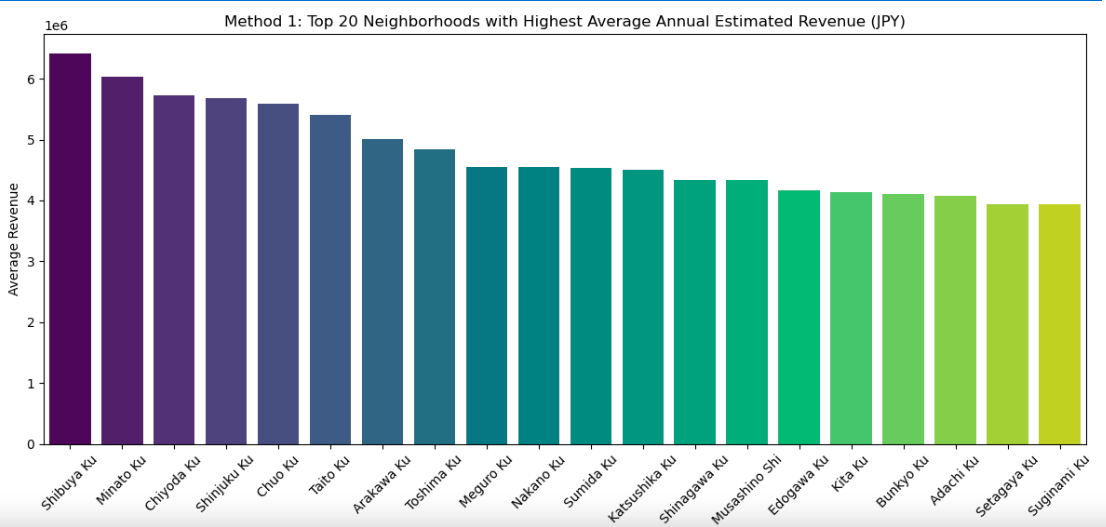

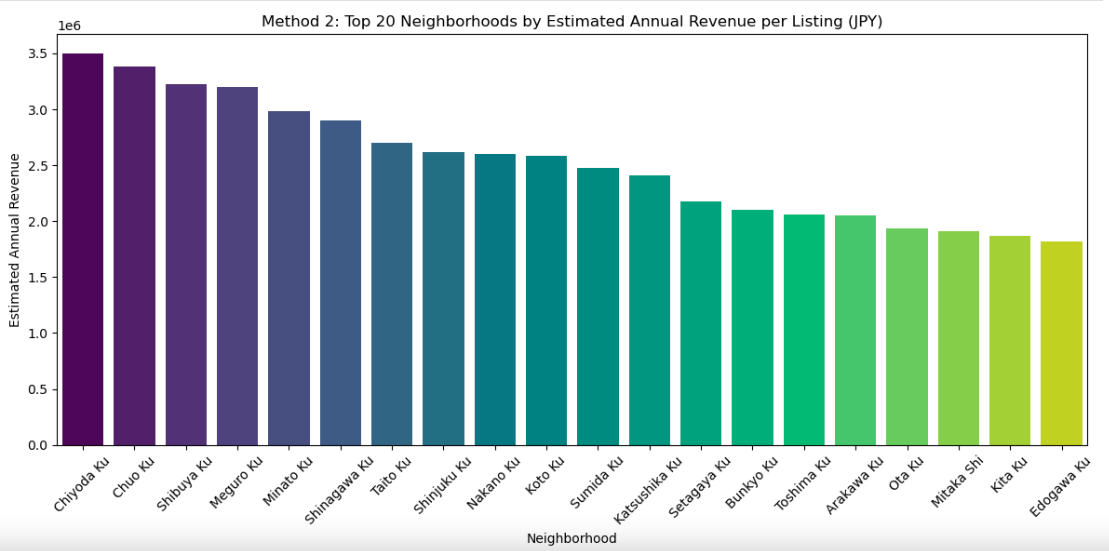

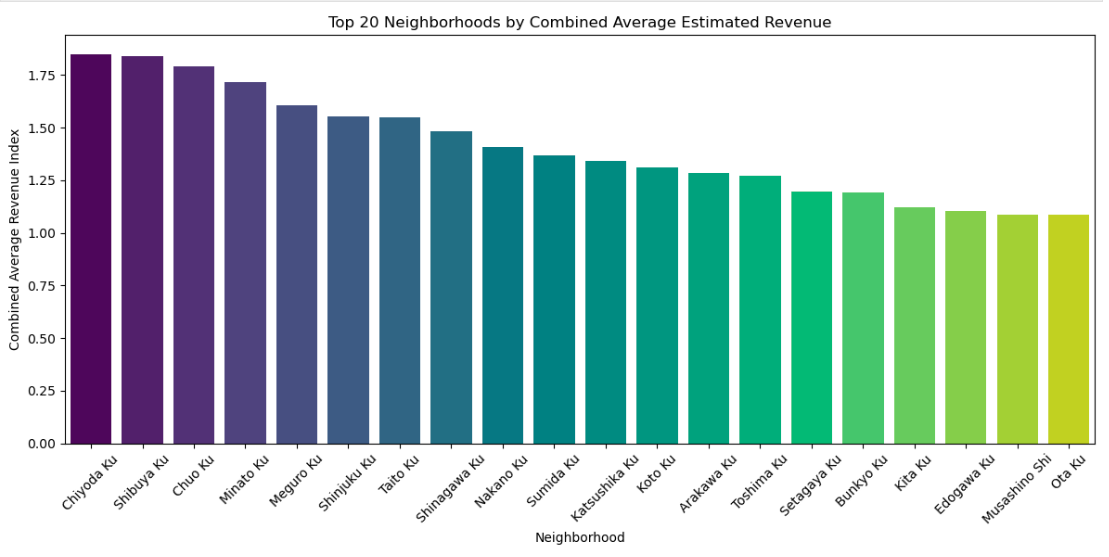

**Findings / 発見:** 

**Consistent top group:** Chiyoda, Shibuya, Chuo and Minato rank in the top five under both methods, and Taito ranks 6th to 7th under both. Differences between neighbouring areas inside this group are small, so read it as a group, not as an exact order.

**Method-dependent:** Meguro (4th on the realistic estimate, 9th on the upper bound), Shinagawa (6th and 13th) and Shinjuku (8th and 4th) change position depending on the method.

**Middle group:** Sumida (10th), Katsushika (11th) and Koto (12th) on the combined index.

**Revenue and cost:** property prices in the top areas are generally high as well (not measured here), so revenue per yen invested may be lower than the revenue ranking suggests.

<br>

## 結果

**一貫して上位のグループ：** 千代田区、渋谷区、中央区、港区は、どちらの方法でも上位5位以内でした。台東区は両方の方法で6〜7位でした。このグループ内の隣り合うエリアの差は小さいため、厳密な順位ではなく、グループとして見てください。

**方法によって変わるエリア：** 目黒区（現実的な推定で4位、上限値で9位）、品川区（6位と13位）、新宿区（8位と4位）は、方法によって順位が変わります。

**中位のグループ：** 統合した指数では、墨田区（10位）、葛飾区（11位）、江東区（12位）です。

**売上とコスト：** 上位エリアは一般に不動産価格も高い傾向があります（本分析では測定していません）。そのため、投資額あたりの売上は、売上ランキングが示すより低くなる可能性があります。

### Map Visualizations of Most Popular Areas and Areas with Highest Estimated Revenues
### 最も人気のあるエリアと推定収益が最も高いエリアのマップビジュアライゼーション

To see an interactive map press the link below: <br>
インタラクティブマップを見るには、以下のリンクをクリックしてください：<br>

 [View Interactive Map](https://vickylubi.github.io/map_int/)

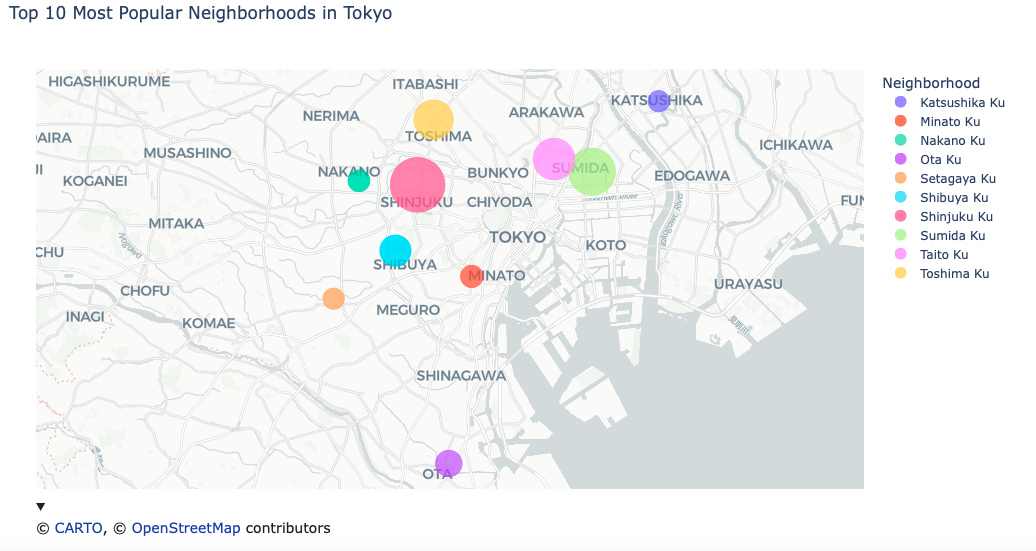

To see an interactive map press the link below: <br>
インタラクティブマップを見るには、以下のリンクをクリックしてください：<br>

[View Interactive Map](https://vickylubi.github.io/int_map_comb/)

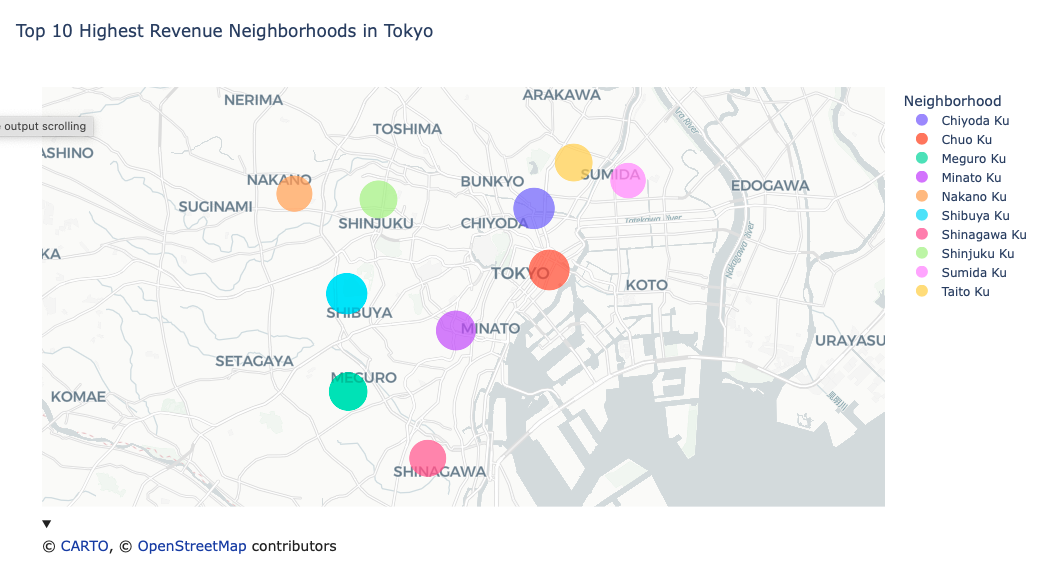

## Recommendations

The ranking is a first screening step. Areas are grouped below by how consistent the evidence is. Statements marked (judgment) are general knowledge or my own assessment, not results from the data.

**Consistently top-ranked: Chiyoda, Shibuya, Chuo, Minato**
- Top five under both methods.
- Shibuya has the highest upper-bound value and ranks 3rd on the realistic estimate. Shibuya and Minato also have the highest median rates among the ten most-listed areas.
- Chiyoda, Chuo and Minato are central business and commercial districts (judgment).
- Purchase prices are likely high in these areas (judgment), which can lower revenue per yen invested.

**Strong but method-dependent: Taito, Meguro, Shinagawa, Shinjuku**
- Taito: 6th to 7th under both methods, with a high median rate among the ten most-listed areas. The most consistent of this group.
- Meguro: 4th on the realistic estimate, 9th on the upper bound.
- Shinagawa: 6th on the realistic estimate, 13th on the upper bound.
- Shinjuku: the most listings, so likely the most competition. 4th on the upper bound, 8th on the realistic estimate.

**Moderate: Sumida, Koto, Katsushika**
- 10th to 12th on the combined index. Usable options, but not standouts in this analysis.

**Property type (judgment):** high-end listings need a larger initial investment, higher maintenance costs and stronger management. Many investors may prefer mid-range listings.

<br>

## おすすめエリア

このランキングは最初の絞り込みの段階です。以下では、根拠の一貫性によってエリアを分けています。「（判断）」と記した内容は、データから導いた結果ではなく、一般的な知識や私の見解です。

**一貫して上位：千代田区、渋谷区、中央区、港区**
- どちらの方法でも上位5位以内です。
- 渋谷区は上限値で最も高く、現実的な推定では3位です。渋谷区と港区は、物件数上位10エリアの中でも中央値が高いエリアです。
- 千代田区、中央区、港区は都心のビジネス・商業地区です（判断）。
- これらのエリアは物件の購入価格も高いと考えられ（判断）、投資額あたりの売上は低くなる可能性があります。

**有望だが方法によって変わる：台東区、目黒区、品川区、新宿区**
- 台東区：どちらの方法でも6〜7位で、物件数上位10エリアの中でも中央値が高いエリアです。このグループで最も一貫しています。
- 目黒区：現実的な推定で4位、上限値で9位です。
- 品川区：現実的な推定で6位、上限値で13位です。
- 新宿区：物件数が最も多く、競合も最も多いと考えられます。上限値で4位、現実的な推定で8位です。

**中程度：墨田区、江東区、葛飾区**
- 統合した指数で10〜12位です。選択肢にはなりますが、本分析で突出したエリアではありません。

**物件タイプ（判断）：** 高価格帯の物件は、初期投資、維持費、運営体制の負担が大きくなります。多くの投資家にとっては、中価格帯の物件が検討しやすいと考えられます。

## Limitations and next steps

- Revenue is estimated from reviews and availability. There is no booking data, and revenue is not profit.
- The review-based estimate rests on two assumptions (50% review rate, 3-night stays).
- Only listings with at least one review in the last 12 months are included (about 88% of short-stay listings), so figures describe listings that were booked.
- About 11% of prices were filled in from similar listings, and price outliers were removed, which excludes part of the luxury segment.
- Area values are averages of skewed data, so a few high-earning listings raise them. Medians and sample sizes per area would be more robust.
- Regulation: Japan's home-sharing (minpaku) rules cap rental nights at 180 per year, and some areas are stricter. No cap is applied here, and the license field was not used. Check current rules before investing.
- One snapshot (December 2024). Tourism demand in Tokyo can change quickly.

**Next steps:** add purchase prices and operating costs to estimate yield; add seasonality and events; model listing-level effects (room type, size, area) to separate location from property characteristics.

<br>

## 制約と今後の課題

- 売上はレビューと空き状況から推定したものです。予約データはなく、売上は利益ではありません。
- レビューに基づく推定は、2つの仮定（レビュー率50%、平均3泊）に基づいています。
- 過去12か月に1件以上のレビューがある物件のみを対象としています（短期滞在物件の約88%）。そのため、数値は予約が入った物件の状況を表しています。
- 価格の約11%は類似物件から補完し、価格の外れ値は除外しました。これにより高価格帯の一部が除かれています。
- エリアごとの値は偏りのあるデータの平均値であり、一部の高収益物件に引き上げられます。エリアごとの中央値とサンプルサイズを示すほうが頑健です。
- 規制：日本の住宅宿泊事業（民泊）では、年間の営業日数が180日までに制限されており、エリアによってはさらに厳しい規制があります。本分析では上限を適用しておらず、ライセンス情報も使用していません。投資前に最新の規制を確認してください。
- 2024年12月時点の1回分のデータです。東京の観光需要は短期間で変化し得ます。

**今後の課題：** 購入価格と運営コストを加えて利回りを推定すること。季節性やイベントの影響を加えること。物件単位のモデル（部屋タイプ、広さ、エリア）で、立地と物件特性の影響を分けること。

## Conclusion

Chiyoda, Shibuya, Chuo and Minato have the highest estimated revenue per listing under both methods, with Taito close behind. Meguro, Shinagawa and Shinjuku depend on the method. Because purchase prices, operating costs and regulation are not included, the ranking is a first screening step for deciding which areas to analyze further.

<br>

## まとめ

推定売上が最も高いのは、どちらの方法でも千代田区、渋谷区、中央区、港区で、台東区がそれに続きます。目黒区、品川区、新宿区は方法によって順位が変わります。購入価格、運営コスト、規制は含まれていないため、このランキングは、どのエリアをさらに詳しく分析するかを決めるための最初の絞り込みとして位置づけられます。

## Appendix A: Data preparation

- Converted data types (price, host rates)
- Filled missing prices (about 11% of listings) with the median for the same area, property type and number of bedrooms
- Filled missing bedroom counts (1 for private, shared and hotel rooms; median by guest capacity for entire homes)
- Dropped columns not used in the analysis
- Removed price outliers above about ¥[upper] (1.5 × IQR rule)
- Removed long stays (minimum stay of 10 nights or more)
- Kept active listings only: at least one review in the last 12 months
- Kept areas with more than 20 such listings

## 付録A：データ準備

- データ型を変換（価格、ホストの各種比率など）
- 価格の欠損（約11%）を、同じエリア・物件タイプ・寝室数の中央値で補完
- 寝室数の欠損を補完（個室・相部屋・ホテルルームは1、まるごと貸しは宿泊定員別の中央値）
- 分析に使用しない列を削除
- 約[upper]円を超える価格の外れ値を除外（四分位範囲の1.5倍の基準）
- 長期滞在（最低宿泊日数10日以上）を除外
- 稼働中の物件のみを対象とし、過去12か月に1件以上のレビューがある物件に限定
- 該当物件が20件を超えるエリアのみを対象
  